# Important Installs

In [ ]:
!pip install evaluate
!pip install rouge_score

# Imports

In [ ]:
import tarfile
import os
import matplotlib.pyplot as plt
from wordcloud import WordCloud

import torch
import torch.nn as nn
from torch.optim import AdamW, Adam
from datasets import load_dataset
from transformers import BartForConditionalGeneration, BartTokenizer

import evaluate
from tqdm import tqdm

# Universal Variables

This is to ensure reproducibility

## setting up google drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## set device to cuda if available, else default to CPU

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Setting Random Seed

In [ ]:
RANDOM_SEED = 42

torch.manual_seed(RANDOM_SEED)
torch.cuda.manual_seed(RANDOM_SEED)

## Links / Paths

In [ ]:
zippedDataSetPath = '/content/drive/MyDrive/Natural_Language_Processing/Dataset/english_XLSum_v2.0.tar.bz2'
extractedDataSetPath = '/content/xlsum_en_dataset'

modelSavePath = '/content/drive/MyDrive/Natural_Language_Processing/Model_Saves'

## Hyper parameters

In [ ]:
MODEL_RUN_FILENAME = 'Bart-Summarisation-Final-3.pth'

MAX_SUMMARY_LENGTH = 64
MAX_INPUT_LENGTH = 512

BEAM_SEARCH_WIDTH = 4

BATCH_SIZE = 128
EPOCHS = 1

LEARNING_RATE = 1e-5

# Extracting and Loading Dataset

In [ ]:
# Create Directory if it does not exist
os.makedirs(extractedDataSetPath, exist_ok=True)

# Extract the tar file
with tarfile.open(zippedDataSetPath, 'r:bz2') as tar:
    tar.extractall(path=extractedDataSetPath)

print("Files have been successfully extracted.")

/tmp/ipykernel_53518/1810096438.py:6: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=extractedDataSetPath)


Files have been successfully extracted.


In [ ]:
xlsumEnDataset = load_dataset('json', data_files={
    'train': os.path.join(extractedDataSetPath, 'english_train.jsonl'),
    'test': os.path.join(extractedDataSetPath, 'english_test.jsonl'),
    'val': os.path.join(extractedDataSetPath, 'english_val.jsonl')
})

In [ ]:
print(xlsumEnDataset['train'][0]['title'])
print(xlsumEnDataset['train'][0]['summary'])
print(xlsumEnDataset['train'][0]['text'])

Weather alert issued for gale force winds in Wales
Winds could reach gale force in Wales with stormy weather set to hit the whole of the country this week.
The Met Office has issued a yellow weather warning for wind covering Wales and England, starting from 21:00 GMT on Wednesday evening. Travel and power are both likely to be disrupted, with the warning to remain in place until 15:00 on Thursday. Gusts of 55mph (88kmh) are likely and could hit up to 70mph on coasts and hills, with heavy and blustery showers.


# Initilising tokenizer and Model

In [ ]:
tokenizer = BartTokenizer.from_pretrained('facebook/bart-base')

# Since we are generating text for summerization, we shall be using the BartForConditionalGenration specifically
model = BartForConditionalGeneration.from_pretrained('facebook/bart-base')

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Loading weights:   0%|          | 0/259 [00:00<?, ?it/s]

## Defining tokenize function for dataset tokenization

In [ ]:
def tokenize(batch):
  # We shall truncate the input text to Bart's max length, which is 1024
  modelInput = tokenizer(batch['text'],padding='max_length',truncation=True,max_length=MAX_INPUT_LENGTH)
  # And truncate the summary to a length of 128
  labels = tokenizer(batch['summary'],padding='max_length',truncation=True,max_length=MAX_SUMMARY_LENGTH)

  modelInput['labels'] = labels['input_ids']
  return modelInput


## Actual mapping of tokenize function

In [ ]:
trainDs = xlsumEnDataset['train'].map(tokenize,batched=True)
testDs = xlsumEnDataset['test'].map(tokenize,batched=True)
valDs = xlsumEnDataset['val'].map(tokenize,batched=True)

Map:   0%|          | 0/306522 [00:00<?, ? examples/s]

Map:   0%|          | 0/11535 [00:00<?, ? examples/s]

Map:   0%|          | 0/11535 [00:00<?, ? examples/s]

In [ ]:
trainDs.set_format('torch',columns=['input_ids','attention_mask','labels'])
testDs.set_format('torch',columns=['input_ids','attention_mask','labels'])
valDs.set_format('torch',columns=['input_ids','attention_mask','labels'])

# Visualization of training, test and validation datasets

In [ ]:
# Extract text from the tokenised dataset and store it in arrays
trainText = [tokenizer.decode(ids,skip_special_tokens=True) for ids in trainDs['input_ids']]
testText = [tokenizer.decode(ids,skip_special_tokens=True) for ids in testDs['input_ids']]
valText = [tokenizer.decode(ids,skip_special_tokens=True) for ids in valDs['input_ids']]

In [ ]:
# Combine all the arrays into a single long string
combTrainText = ' '.join(trainText)
combTestText = ' '.join(testText)
combValText = ' '.join(valText)

In [ ]:
wordcloudTrain = WordCloud(width=800,height=400).generate(combTrainText)
wordcloudTest = WordCloud(width=800,height=400).generate(combTestText)
wordcloudVal = WordCloud(width=800,height=400).generate(combValText)

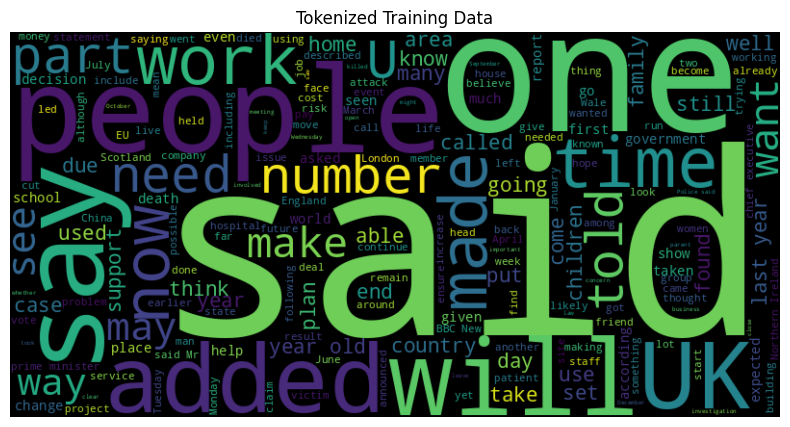

In [ ]:
plt.figure(figsize=(10,5))
plt.imshow(wordcloudTrain,interpolation='bilinear')
plt.axis('off')
plt.title('Tokenized Training Data')
plt.show()

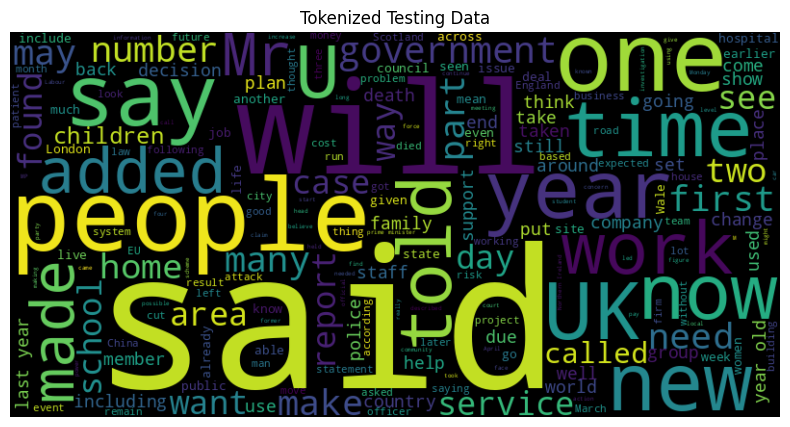

In [ ]:
plt.figure(figsize=(10,5))
plt.imshow(wordcloudTest,interpolation='bilinear')
plt.axis('off')
plt.title('Tokenized Testing Data')
plt.show()

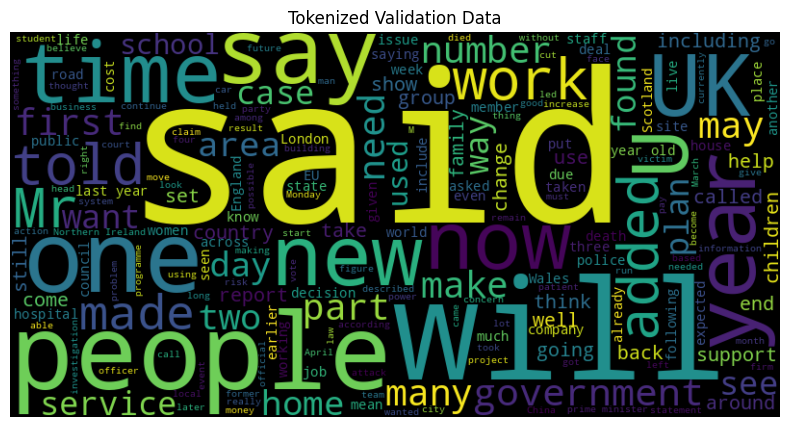

In [ ]:
plt.figure(figsize=(10,5))
plt.imshow(wordcloudVal,interpolation='bilinear')
plt.axis('off')
plt.title('Tokenized Validation Data')
plt.show()

# Optimizer

In [ ]:
# We will be choosing adamw, as from previous experimentations it has consistentaly performed better

optimizer = AdamW(model.parameters(), lr=LEARNING_RATE)

# Training function

In [ ]:
def train(model, trainLoader, optimizer, device):
  torch.cuda.empty_cache()
  model.train()

  for batch in tqdm(trainLoader, desc="Training"):
    inputId = batch['input_ids'].to(device)
    attentionMask = batch['attention_mask'].to(device)
    labels = batch['labels'].to(device)

    # setting optimizer to zero grad, so gradient from previous iteration are not taken forward
    optimizer.zero_grad()
    output = model(input_ids=inputId, attention_mask=attentionMask, labels=labels)
    loss = output.loss
    loss.backward()
    optimizer.step()

# Evaluating Model Function

We shall be using the rouge metric, as it is considered the baseline metric for text summerisation models

In [ ]:
def evaluate_model(model,testLoader,tokenizer, device):
  model.eval()
  rougeMetric = evaluate.load('rouge')

  generatedSummary = []
  originalSummary = []

  # setting torch to not use gradients
  with torch.no_grad():
    for batch in tqdm(testLoader, desc="Evaluating"):
      inputId = batch['input_ids'].to(device)
      attentionMask = batch['attention_mask'].to(device)
      labels = batch['labels'].to(device)

      # replace errors for padding
      labels = torch.where(labels != -100, labels, tokenizer.pad_token_id)

      # when generating summary, we set the max length of summary the same as initilised and bean search width to be 4 and we set early stopping to be true incase there is no improvement
      generatedId = model.generate(input_ids = inputId, attention_mask = attentionMask, max_length=MAX_SUMMARY_LENGTH, num_beams=BEAM_SEARCH_WIDTH, early_stopping=True)

      # decoding the original and generated inputIds
      decodedGeneratedSummary = tokenizer.batch_decode(generatedId,skip_special_tokens=True)
      decodedOriginalSummary = tokenizer.batch_decode(labels,skip_special_tokens=True)

      # Filter out any None values or empty strings to prevent errors in the evaluate library
      decodedGeneratedSummary = [s for s in decodedGeneratedSummary if s is not None and s.strip() != '']
      decodedOriginalSummary = [s for s in decodedOriginalSummary if s is not None and s.strip() != '']

      generatedSummary.extend(decodedGeneratedSummary)
      originalSummary.extend(decodedOriginalSummary)


  # Computing rouge scores, while considering words with the same stem to be equal
  result = rougeMetric.compute(predictions=generatedSummary, references=originalSummary, use_stemmer=True)

  return result

# Loading the model, training and testing datasets

In [ ]:
torch.cuda.empty_cache()

In [ ]:

model.to(device)

trainLoader = torch.utils.data.DataLoader(trainDs, batch_size=BATCH_SIZE, shuffle=True)
testLoader = torch.utils.data.DataLoader(testDs, batch_size=BATCH_SIZE, shuffle=True)

# Actual Training Loop

In [ ]:
for epoch in range(EPOCHS):
  print(f'Epoch {epoch+1}/{EPOCHS}')
  train(model, trainLoader, optimizer, device)

  print(f'Evaluating Epoch {epoch+1}/{EPOCHS}')
  rougeScore = evaluate_model(model, testLoader, tokenizer, device)

  print(f'Epoch {epoch+1}/{EPOCHS} - ROUGE Score:{rougeScore}')

Epoch 1/1


Training: 100%|██████████| 2395/2395 [1:02:07<00:00,  1.56s/it]


Evaluating Epoch 1/1


Evaluating: 100%|██████████| 91/91 [07:22<00:00,  4.86s/it]


Epoch 1/1 - ROUGE Score:{'rouge1': np.float64(0.36966614940056436), 'rouge2': np.float64(0.14544087721626114), 'rougeL': np.float64(0.2927964849357508), 'rougeLsum': np.float64(0.29288699219278985)}


# Saving the Model

In [ ]:
torch.save(model.state_dict(), os.path.join(modelSavePath, MODEL_RUN_FILENAME))
